# The Market Model: Beta and CAPM in Practice

**From CAPM theory to market data**

In the slides, we explained why the CAPM relates expected return to systematic risk. Here we **estimate beta from excess returns**, investigate how much risk the market explains, and examine whether beta changes over time.

We will use Yahoo Finance prices and the daily risk-free return (`RF`) from the Kenneth French Data Library.

## 1. The Market Model: A Quick Reminder

We estimate a regression using **returns above the risk-free rate**:

$$
R_{i,t}-R_{f,t}=\alpha_i+\beta_i(R_{M,t}-R_{f,t})+\varepsilon_{i,t}
$$

- **Beta:** how sensitive the stock's excess return is to the market's excess return.
- **Alpha:** intercept; under the CAPM, expected alpha is zero.
- **$R^2$:** fraction of the variation in the stock's excess return explained by the regression.

**Question:** How can we estimate these values with real data?

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import yfinance as yf
from pandas_datareader import data as web

# If needed, run once: %pip install yfinance pandas-datareader statsmodels

## 2. Estimating Beta: Endesa and the IBEX 35

Start with a familiar example: **Endesa versus the IBEX 35**. Download their adjusted prices and align the returns with the Fama–French daily risk-free series.

*Data note:* Fama–French `RF` is a **US-dollar short-term rate**. It is used here only as a simple classroom proxy for the Spanish example; a euro risk-free series is preferable for euro-based valuation.

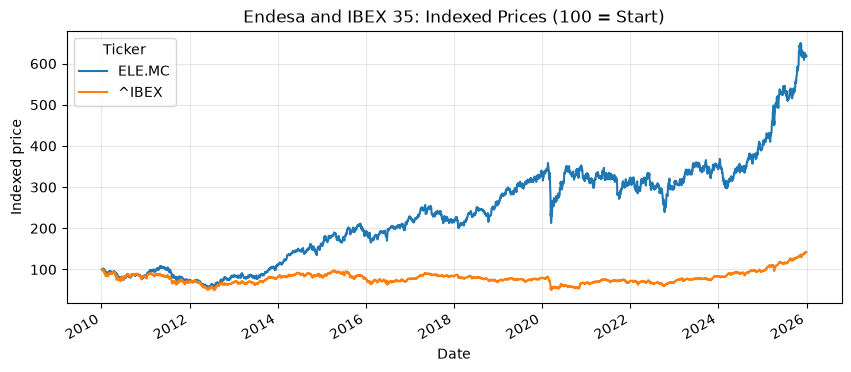

In [11]:
# Daily risk-free returns from Kenneth French (% -> decimal)
ff = web.DataReader('F-F_Research_Data_Factors_daily', 'famafrench',
                    start='2010-01-01')[0]
rf_daily = ff['RF'] / 100
rf_daily.index = rf_daily.index.to_timestamp()
rf_daily.name = 'RF'

# Adjusted prices: Endesa and IBEX 35
prices_es = yf.download(['ELE.MC', '^IBEX'], start='2010-01-01',
                        end='2026-01-01', auto_adjust=True,
                        progress=False)['Close'].dropna()

# Match trading dates before computing excess returns
returns_es = prices_es.pct_change(fill_method=None).dropna()
data_es = returns_es.join(rf_daily).dropna()
excess_es = data_es[['ELE.MC', '^IBEX']].sub(data_es['RF'], axis=0)
# excess_es = data_es[['ELE.MC', '^IBEX']] - data_es[['RF']].to_numpy()

(100 * prices_es / prices_es.iloc[0]).plot(figsize=(10, 4))
plt.title('Endesa and IBEX 35: Indexed Prices (100 = Start)')
plt.ylabel('Indexed price')
plt.grid(alpha=0.3)
plt.show()

### Two ways to estimate the same beta

The regression slope can also be obtained directly from the covariance of the two excess-return series. Both estimates should agree when the OLS regression includes an intercept.

In [12]:
# Covariance formula
beta_cov = (excess_es['ELE.MC'].cov(excess_es['^IBEX']) /
            excess_es['^IBEX'].var())

# OLS: Endesa excess return against IBEX excess return
X = sm.add_constant(excess_es['^IBEX'])
model = sm.OLS(excess_es['ELE.MC'], X).fit()

print(f'Beta from covariance: {beta_cov:.3f}')
print(f'Beta from OLS:        {model.params["^IBEX"]:.3f}')
print(f'Daily alpha:          {model.params["const"]:.5f}')
print(f'R-squared:           {model.rsquared:.2%}')

Beta from covariance: 0.664
Beta from OLS:        0.664
Daily alpha:          0.00042
R-squared:           38.52%


In [13]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 ELE.MC   R-squared:                       0.385
Model:                            OLS   Adj. R-squared:                  0.385
Method:                 Least Squares   F-statistic:                     2495.
Date:                Thu, 12 Nov 2026   Prob (F-statistic):               0.00
Time:                        10:00:11   Log-Likelihood:                 12219.
No. Observations:                3984   AIC:                        -2.443e+04
Df Residuals:                    3982   BIC:                        -2.442e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0004      0.000      2.342      0.0

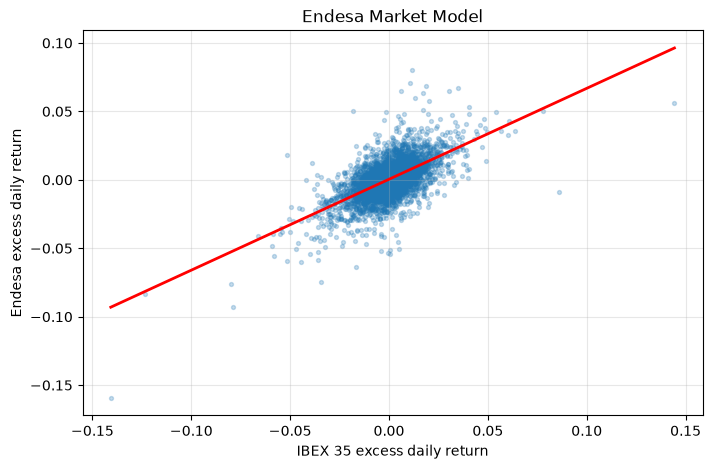

In [14]:
# Scatter plot and fitted regression line
plt.figure(figsize=(8, 5))
plt.scatter(excess_es['^IBEX'], excess_es['ELE.MC'], s=8, alpha=0.25)
x_line = np.linspace(excess_es['^IBEX'].min(), excess_es['^IBEX'].max(), 100)
y_line = model.params['const'] + model.params['^IBEX'] * x_line
plt.plot(x_line, y_line, color='red', linewidth=2)
plt.xlabel('IBEX 35 excess daily return')
plt.ylabel('Endesa excess daily return')
plt.title('Endesa Market Model')
plt.grid(alpha=0.3)
plt.show()

## 3. Interpreting the Regression

Read the regression output. Focus on **alpha**, **beta**, the **95% confidence interval for beta**, and **$R^2$**.

**Exercise:** Is Endesa more or less sensitive than the market? Does the confidence interval include 1?

In [15]:
print(model.summary())
print('95% confidence interval for beta:')
print(model.conf_int().loc['^IBEX'])

                            OLS Regression Results                            
Dep. Variable:                 ELE.MC   R-squared:                       0.385
Model:                            OLS   Adj. R-squared:                  0.385
Method:                 Least Squares   F-statistic:                     2495.
Date:                Thu, 12 Nov 2026   Prob (F-statistic):               0.00
Time:                        10:00:12   Log-Likelihood:                 12219.
No. Observations:                3984   AIC:                        -2.443e+04
Df Residuals:                    3982   BIC:                        -2.442e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0004      0.000      2.342      0.0

## 4. Systematic and Idiosyncratic Risk

For a one-factor OLS regression with an intercept, the variance of a stock's excess return can be divided into:

$$\operatorname{Var}(R_i-R_f)=\beta_i^2\operatorname{Var}(R_M-R_f)+\operatorname{Var}(\varepsilon_i).$$

**Exercise:** What fraction of Endesa's variance is associated with the market?

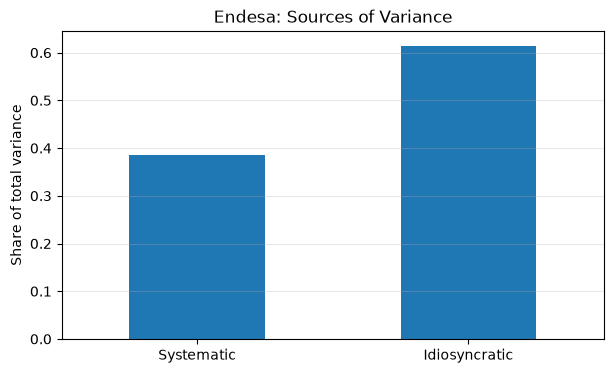

Systematic share: 38.5%
R-squared:        38.5%


In [16]:
# Variance explained by the market and residual variance
systematic_var = model.params['^IBEX']**2 * excess_es['^IBEX'].var()
specific_var = model.resid.var()
total_var = excess_es['ELE.MC'].var()

risk_parts = pd.Series({
    'Systematic': systematic_var / total_var,
    'Idiosyncratic': specific_var / total_var
})
risk_parts.plot.bar(rot=0, figsize=(7, 4))
plt.title('Endesa: Sources of Variance')
plt.ylabel('Share of total variance')
plt.grid(axis='y', alpha=0.3)
plt.show()
print(f'Systematic share: {risk_parts["Systematic"]:.1%}')
print(f'R-squared:        {model.rsquared:.1%}')

## 5. Comparing Stocks: Are Betas Similar?

**Exercise:** Compare Amazon (`AMZN`), Coca-Cola (`KO`) and Microsoft (`MSFT`) using the S&P 500 as the market proxy. Estimate their monthly alpha, beta and $R^2$ from excess returns.

For the US exercise, the Fama–French risk-free series is denominated consistently with the assets.

In [26]:
stocks = ['AMZN', 'KO', 'MSFT']
market = '^GSPC'



## 6. Rolling Betas: Does Exposure Change Over Time?

A single regression summarizes one historical period. **Does beta remain stable?**

Estimate a beta each month using the **preceding 60 monthly observations**, and compare the trajectories for our three stocks.

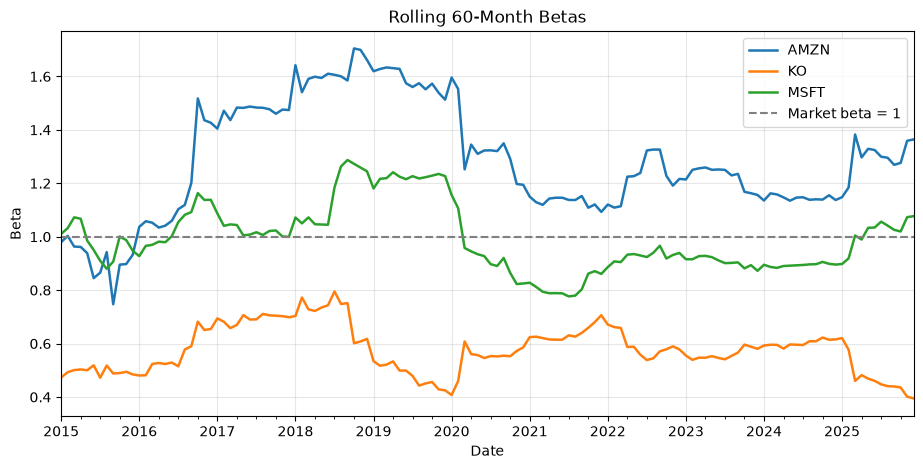

In [23]:
# Rolling beta: covariance divided by market variance
window = 60
market_var = excess_us[market].rolling(window).var()

rolling_betas = pd.DataFrame(index=excess_us.index)
for stock in stocks:
    rolling_betas[stock] = (
        excess_us[stock].rolling(window).cov(excess_us[market]) / market_var
    )
    
rolling_betas = rolling_betas.dropna()

rolling_betas.plot(figsize=(11, 5), linewidth=1.8)
plt.axhline(1, color='gray', linestyle='--', label='Market beta = 1')
plt.title('Rolling 60-Month Betas')
plt.ylabel('Beta')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 7. Sector Betas: Your Turn

**Exercise:** Repeat the 60-month rolling-beta analysis with three ETFs: industrials (`XLI`), aerospace and defense (`ITA`) and energy (`XLE`).

Compare which industry has the highest market sensitivity and whether that ranking changes over time.

In [24]:
sectors = ['XLI', 'ITA', 'XLE']
prices_sector = yf.download(sectors + [market], start='2010-01-01',
                            end='2026-01-01', auto_adjust=True,
                            progress=False)['Close'].dropna()
sector_monthly = prices_sector.resample('ME').last().pct_change(fill_method=None).dropna()
sector_data = sector_monthly.join(rf_monthly).dropna()
sector_excess = sector_data[sectors + [market]].sub(sector_data['RF'], axis=0)

# TODO: Estimate and plot 60-month rolling betas for XLI, ITA, and XLE.
# Use the approach from Section 6.

## 8. Does Data Frequency Matter?

**Exercise:** Re-estimate Endesa's beta using daily, weekly and monthly **excess returns**. Compare the estimates and discuss why they may differ.

Use risk-free returns aggregated to the matching frequency.

In [25]:
# Daily, weekly and monthly data for the Spanish example
frequencies = {'Daily': None, 'Weekly': 'W-FRI', 'Monthly': 'ME'}
frequency_betas = {}

for name, freq in frequencies.items():
    if freq is None:
        excess = excess_es
    else:
        # Returns and RF must cover the same frequency
        stock_returns = prices_es.resample(freq).last().pct_change(fill_method=None)
        rf_period = (1 + rf_daily).resample(freq).prod() - 1
        data = stock_returns.join(rf_period.rename('RF')).dropna()
        excess = data[['ELE.MC', '^IBEX']].sub(data['RF'], axis=0)

    frequency_betas[name] = (
        excess['ELE.MC'].cov(excess['^IBEX']) / excess['^IBEX'].var()
    )

display(pd.Series(frequency_betas, name='Endesa Beta').to_frame().round(3))

,Endesa Beta
Daily,0.664
Weekly,0.682
Monthly,0.659


## 9. From Beta to CAPM Expected Returns

We have estimated how stocks respond to market movements. Now use those betas to calculate the **expected returns implied by the CAPM**:

$$E[R_i]=r_f+\beta_i\big(E[R_M]-r_f\big).$$

**Exercise:** Assume an annual risk-free rate of **3%** and an expected annual market premium of **6%**. Which stock has the highest CAPM expected return?

In [22]:
# Illustrative annual assumptions for the CAPM exercise
rf_annual = 0.03
market_premium = 0.06

capm_table = pd.DataFrame({
    'Beta': stock_results['Beta'],
    'CAPM Expected Return': rf_annual + stock_results['Beta'] * market_premium
})
display(capm_table.style.format({
    'Beta': '{:.2f}',
    'CAPM Expected Return': '{:.2%}'
}))

,Beta,CAPM Expected Return
Asset,,
AMZN,1.22,10.32%
KO,0.50,5.99%
MSFT,1.00,8.98%


## Takeaways

- **Beta** measures the sensitivity of an asset's excess return to the market's excess return.
- The covariance formula and the OLS slope give the same beta for the same data.
- Market and company-specific risks can be separated using the regression.
- Beta may change with the estimation period, industry and return frequency.
- CAPM converts an estimated beta into an expected return **under its equilibrium assumptions**.

**Final question:** What might make a historically estimated beta unreliable for future investment decisions?